<a href="https://colab.research.google.com/github/pazolka/ai-climate-workshop-dhaka/blob/main/template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3. Resampling and validation


When working with data from different sources, we must ensure that their temporal and spatial resolutions are aligned.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*Google will stop supporting.*')

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt

### 3.1. Temporal resampling

BWDB's dataset on groundwater levels has different temporal resolutions. The newest sensors provide sub-daily measurements, and many long-running wells have weekly observations. High-frequency readings are crucial for flood modelling, and monthly or seasonal averages are typically used for water sustainability and security studies.

Let's see how we can resample a GWL record from weekly to monthly frequency, and from weekly to daily.

In [2]:
# Step 1: Read the data
weekly_ts = pd.read_csv('../data/point_observations/MY050_gwl_ts_weekly.csv')

# parse the date
weekly_ts['Date'] = pd.to_datetime({'year': weekly_ts['Year'],
                                    'month': weekly_ts['Month'],
                                    'day': weekly_ts['Day']})

# 1996-1997 appear twice in the record - drop the exact duplicate rows
weekly_ts = weekly_ts.drop_duplicates()
# set the index to the Date column and sort
weekly_ts = weekly_ts.set_index('Date').sort_index()

weekly_ts.head()

,District,Upazila,WellID,OldID,GWT,RefLevel,ParaHt,Year,Month,Day,Week,DecYear
Date,,,,,,,,,,,,
1975-09-29,Mymensingh,Haluaghat,GT6124015,MY050,2.57,15.05,0.68,1975,9,29,39,1975.746064
1975-10-06,Mymensingh,Haluaghat,GT6124015,MY050,2.57,15.05,0.68,1975,10,6,40,1975.766427
1975-10-13,Mymensingh,Haluaghat,GT6124015,MY050,2.62,15.05,0.68,1975,10,13,41,1975.785592
1975-10-20,Mymensingh,Haluaghat,GT6124015,MY050,2.90,15.05,0.68,1975,10,20,42,1975.804757
1975-10-27,Mymensingh,Haluaghat,GT6124015,MY050,3.48,15.05,0.68,1975,10,27,43,1975.823922


In [3]:
# Step 2.1: resample the weekly readings to monthly means

# 'MS' labels each value with the first day of the month
# and then takes the mean of all values in that month
monthly_ts = weekly_ts['GWT'].resample('MS').mean()
# counting how many weekly readings were used to calculate each monthly mean
monthly_counts = weekly_ts['GWT'].resample('MS').count()

print(f'{monthly_ts.notna().sum()} months with data, {monthly_ts.isna().sum()} without')
pd.DataFrame({'GWT': monthly_ts, 'n_obs': monthly_counts}).head(10)

496 months with data, 23 without


,GWT,n_obs
Date,,
1975-09-01,2.5700,1
1975-10-01,2.8925,4
1975-11-01,3.7500,4
1975-12-01,4.6680,5
1976-01-01,NaN,0
1976-02-01,NaN,0
1976-03-01,NaN,0
1976-04-01,NaN,0
1976-05-01,NaN,0


In [4]:
# Step 2.2: resample the weekly readings to daily values using linear interpolation
daily_ts = weekly_ts['GWT'].resample('D').interpolate(method='linear')
daily_ts

Date
1975-09-29    2.570000
1975-09-30    2.570000
1975-10-01    2.570000
1975-10-02    2.570000
1975-10-03    2.570000
                ...   
2018-11-22    4.614286
2018-11-23    4.585714
2018-11-24    4.557143
2018-11-25    4.528571
2018-11-26    4.500000
Freq: D, Name: GWT, Length: 15765, dtype: float64

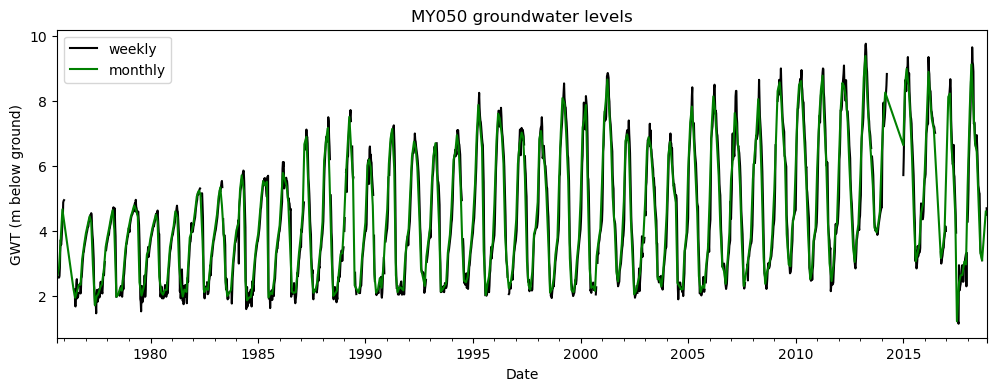

In [5]:
# visualise
fig, ax = plt.subplots(figsize=(12, 4))
#daily_ts.plot(ax=ax, color='tab:red', label='daily') # daily (interpolated)
weekly_ts['GWT'].plot(ax=ax, color='black', label='weekly') # weekly (original)
monthly_ts.plot(ax=ax, color='green', label='monthly') # monthly (averaged)

ax.set_ylabel('GWT (m below ground)')
ax.set_title('MY050 groundwater levels')
ax.legend()
plt.show()

Can you notice that upsampling from weekly to daily time series is essentially a gap-filling task? We chose a simple linear interpolation, but you can experiment with random-forest based imputation and other machine/deep learning methods!

### Bonus: Rainfal product comparison with BMD observations

Precipitation is a fundamental variable in climate research and a key input for many climate-related applications and AI models. However, it is hard to estimate because of its temporal and spatial variability, and the quality of available gridded precipitation products can vary considerably. Comparing these products against local rain gauge observations is needed to assess their accuracy, identify potential biases, and determine which dataset is most suitable for subsequent applications. 

Let's evaluate three gridded monthly precipitation products (BDGR at 0.01°, TerraClimate at 0.05° and ERA5 at 0.25°) and assess their agreement with observed rainfall from BMD weather stations.

In [6]:
# Step 1: Read the point observations data
precip_obs = pd.read_csv('../data/point_observations/BMD_precip_ts_monthly.csv')

# reshape to a monthly time series: Date index, one column per station
precip_obs['Date'] = pd.to_datetime({'year': precip_obs['Year'], 'month': precip_obs['Month'], 'day': 1})
precip_obs = precip_obs.pivot(index='Date', columns='Station', values='Rain').sort_index()
precip_obs.index.name = 'Date'
precip_obs.columns.name = None

print(f'Data shape (months, stations): {precip_obs.shape}')          # 600 months x 35 stations
print(f'Data span: {precip_obs.index[0]} -> {precip_obs.index[-1]}')

# read the accompanying station location data
locations = pd.read_csv('../data/point_observations/BMD_precip_station_info.csv')
locations = locations.set_index('DataName')[['Latitude', 'Longitude']]

# Step 2: Read the gridded data products (already clipped to Bangladesh)
era5  = xr.open_dataset('../data/gridded/ERA5_precip_M_acc_1972_2020_BGD_025.nc').sel(time=slice('2015-01-01', '2018-01-01'))
bdgr  = xr.open_dataset('../data/gridded/BDGR_precip_M_acc_BGD_2000_2018_001.nc').sel(time=slice('2015-01-01', '2018-01-01'))
terra = xr.open_dataset('../data/gridded/TerraClimate_precip_aet_M_1972_2019_BGD_005.nc').sel(time=slice('2015-01-01', '2018-01-01'))

for name, ds in [('ERA5', era5), ('BDGR', bdgr), ('TerraClimate', terra)]:
    print(f'{name:13s} {dict(ds.sizes)}')

Data shape (months, stations): (36, 35)
Data span: 2016-01-01 00:00:00 -> 2018-12-01 00:00:00


ERA5          {'time': 37, 'lat': 25, 'lon': 20}
BDGR          {'time': 36, 'lat': 600, 'lon': 463}
TerraClimate  {'time': 37, 'lat': 118, 'lon': 120}


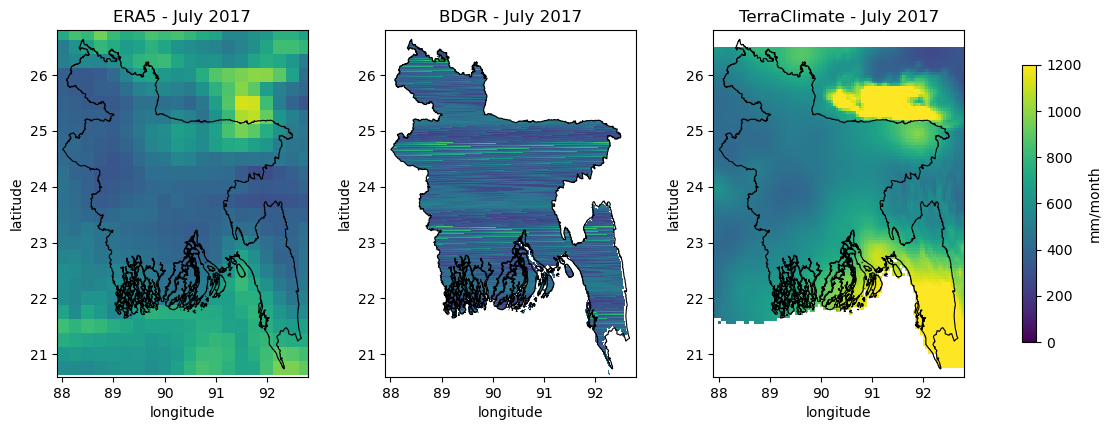

In [7]:
# Visual grid comparison
bgd_shp = gpd.read_file('../data/BGD_shp/Bangladesh.shp')

layers = [
    ('ERA5', era5['pr'].sel(time='2017-07')),
    ('BDGR', bdgr['pr'].sel(time='2017-07')),
    ('TerraClimate', terra['pr'].sel(time='2017-07')),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, da) in zip(axes, layers):
    im = da.plot(ax=ax, cmap='viridis', vmin=0, vmax=1200, add_colorbar=False)
    bgd_shp.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.8)
    ax.set_title(f'{name} - July 2017')
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    ax.set_xlim(87.9, 92.8)
    ax.set_ylim(20.6, 26.8)
fig.colorbar(im, ax=axes, label='mm/month', shrink=0.8)
plt.show()

All datasets provide monthly precipitation values, but their timestamps are not fully aligned. BDGR reports monthly values with timestamps on the 15th of each month, whereas BMD, ERA5 and Terraclimate data use the 1st of each month. For consistency, we shift all timestamps to the 1st of the corresponding month. However, this is a temporal alignment assumption that may introduce some bias, particularly if the datasets differ in how monthly precipitation periods are defined.

The evaluation is performed using all station-month pairs for which both an observed and a gridded precipitation value are available. The following metrics are calculated:

- _r_ and _r\_anom_ - Pearson correlation coefficients calculated using raw precipitation values and precipitation anomalies, respectively. Anomalies are obtained by removing each station's mean seasonal cycle.

- _RMSE_ and _MAE_ - Root Mean Square Error and Mean Absolute Error, expressed in mm/month.

In [8]:
# convert location data into xarray-specific format for sampling
station_names = [s for s in precip_obs.columns if s in locations.index]
station_lat = xr.DataArray(locations.loc[station_names, 'Latitude'].values, dims='station')
station_lon = xr.DataArray(locations.loc[station_names, 'Longitude'].values, dims='station')
station_ids = xr.DataArray(station_names, dims='station')


def sample_grid(ds):
    """Sample the precipitation grid at the station coordinates (nearest cell)."""
    sampled = (ds['pr']
               .sel(lat=station_lat, lon=station_lon, method='nearest')
               .assign_coords(station=station_ids)
               .rename(time='date'))
    # use .interp(...) instead of .sel(..., method='nearest') for bilinear sampling
    # snap every product to the first of the month
    sampled = sampled.assign_coords(
        date=pd.to_datetime(sampled.date.values).to_period('M').to_timestamp())
    # one row per station-month
    return sampled.to_dataframe(name='grid').reset_index()[['station', 'date', 'grid']]


# preview: ERA5 sampled at every station
sample_grid(era5).head()

,station,date,grid
0,Ambagan(Ctg),2015-01-01,8.159637
1,Barisal,2015-01-01,10.406494
2,Bhola,2015-01-01,9.460449
3,Bogra,2015-01-01,9.696960
4,Chandpur,2015-01-01,4.316330


In [9]:
# validation code is exported to a helper module
from validation_helpers import validation_metrics

products = [('ERA5', era5), ('BDGR', bdgr), ('TerraClimate', terra)]

# observations in long format: one row per station-month
obs_long = (precip_obs.rename_axis(index='date', columns='station')
              .melt(ignore_index=False, var_name='station', value_name='obs')
              .reset_index())

summary = {}
for name, ds in products:
    grid = sample_grid(ds)
    pair = obs_long.merge(grid, on=['station', 'date'], how='inner')
    summary[name] = validation_metrics(pair)

summary = pd.DataFrame.from_dict(summary, orient='index').rename_axis('product')
summary[['n_pairs', 'stations']] = summary[['n_pairs', 'stations']].astype(int)
summary.round(3)

,n_pairs,stations,r,r_anom,rmse,mae
product,,,,,,
ERA5,850,34,0.875,0.578,125.098,75.496
BDGR,768,32,0.728,0.443,181.866,96.361
TerraClimate,850,34,0.897,0.723,113.244,69.396


### Summary

- Raw correlations are inflated by the shared seasonal cycle; the anomaly correlation is the fairer measure of month-to-month skill.
- **TerraClimate** has the smallest MAE and highest correclation, closely followed by **ERA5**; they capture the seasonal cycle well in the study period 2016-2018.
- **BDGR** agrees least with the stations despite its 0.01° grid. Adjacent 0.01° rows of the product are almost uncorrelated (horizontal banding visible in many time steps, e.g. July 2017). It is also the only product timestamped on the 15th of the month, so this half-month offset may contribute to its lower score.